# 03 — Astronomical features

## Purpose

This notebook constructs the time and astronomical features used in the forecasting study. We prepare three feature groups:

- **F1:** Gregorian calendar information, such as hour, weekday, and time of year.
- **F2:** solar position and whether the Sun is above the horizon.
- **F3:** continuous lunar and Sun–Moon astronomical information.

These features depend on timestamps and the SOLETE site location. The same continuous astronomical information provides the starting point for the Panchang categories in Notebook 04.

## 1. Load the SOLETE timeline

We use the 5-minute SOLETE timestamps in UTC. Solar and lunar calculations use the SOLETE site at **55.6867° N, 12.0985° E**.

Each 5-minute row is represented astronomically at **two minutes after its recorded timestamp**, an interval-representative convention established by the earlier cross-resolution analysis. We retain the recorded timestamp as the table index.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Locate the project directory from VS Code.
PROJECT_ROOT = next(
    (
        directory
        for directory in [Path.cwd(), *Path.cwd().parents]
        if (directory / "solete_dataset" / "SOLETE_Pombo_5min.h5").is_file()
        and (directory / "src" / "astronomy_features.py").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the SOLETE project.")
PROJECT_ROOT = PROJECT_ROOT.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_solete
from src.preprocessing import build_gregorian_features
from src.astronomy_features import (
    SOLETE_LATITUDE_DEG,
    SOLETE_LONGITUDE_DEG,
    SOLETE_ASTRONOMY_OFFSET,
    solete_astronomy_reference_times,
    build_solar_f2_features,
    load_jpl_ephemeris,
    build_lunar_f3_features,
    tropical_longitudes_for_solete,
    moon_sun_phase_angle_deg,
)

source = load_solete(
    PROJECT_ROOT / "solete_dataset" / "SOLETE_Pombo_5min.h5"
).sort_index()
timestamps = pd.DatetimeIndex(source.index)
assert timestamps.tz is not None
assert timestamps.is_monotonic_increasing and timestamps.is_unique
assert (timestamps[1:] - timestamps[:-1] == pd.Timedelta(minutes=5)).all()
assert len(source) == 131617

reference_times = solete_astronomy_reference_times(timestamps)
assert reference_times.equals(timestamps + pd.Timedelta(minutes=2))
assert SOLETE_ASTRONOMY_OFFSET == pd.Timedelta(minutes=2)

print("Observations:", len(timestamps))
print("Site:", SOLETE_LATITUDE_DEG, "°N,", SOLETE_LONGITUDE_DEG, "°E")
display(pd.DataFrame({
    "recorded_UTC": timestamps[:4],
    "astronomical_reference_UTC": reference_times[:4],
}))


Observations: 131617
Site: 55.6867 °N, 12.0985 °E


,recorded_UTC,astronomical_reference_UTC
0,2018-06-01 00:00:00+00:00,2018-06-01 00:02:00+00:00
1,2018-06-01 00:05:00+00:00,2018-06-01 00:07:00+00:00
2,2018-06-01 00:10:00+00:00,2018-06-01 00:12:00+00:00
3,2018-06-01 00:15:00+00:00,2018-06-01 00:17:00+00:00


## 2. Gregorian calendar features (F1)

Gregorian features describe daily, weekly, and annual position. Cyclic sine and cosine values make the end and start of each cycle close together; for example, 23:55 and 00:00 are adjacent times.

The Gregorian block contains **15 variables**.

In [2]:
f1 = build_gregorian_features(timestamps)

assert f1.index.equals(timestamps)
assert f1.shape == (len(timestamps), 15)
assert f1.columns.is_unique
assert np.isfinite(f1.to_numpy(dtype=float)).all()

print("Gregorian variables:", f1.shape[1])
display(f1.head(3))


Gregorian variables: 15


,utc_year,utc_month,utc_day,utc_day_of_week,utc_day_of_year,utc_hour,utc_minute,utc_minute_of_day,utc_is_weekend,utc_time_sin,utc_time_cos,utc_weekday_sin,utc_weekday_cos,utc_year_sin,utc_year_cos
Timestamp,,,,,,,,,,,,,,,
2018-06-01 00:00:00+00:00,2018,6,1,4,152,0,0,0,0,0.000000,1.000000,-0.433884,-0.900969,0.516062,-0.856551
2018-06-01 00:05:00+00:00,2018,6,1,4,152,0,5,5,0,0.021815,0.999762,-0.433884,-0.900969,0.516011,-0.856582
2018-06-01 00:10:00+00:00,2018,6,1,4,152,0,10,10,0,0.043619,0.999048,-0.433884,-0.900969,0.515960,-0.856613


## 3. Solar features (F2)

Solar position is calculated from UTC time and the SOLETE location using the NREL solar-position algorithm through `pvlib`.

The five variables added in F2 are solar elevation, cosine of zenith, sine and cosine of azimuth, and a daylight indicator. Positive solar elevation denotes the Sun above the geometric horizon.

In [3]:
f2 = build_solar_f2_features(timestamps)

assert f2.index.equals(timestamps)
assert f2.shape == (len(timestamps), 5)
assert f2.columns.is_unique
assert np.isfinite(f2.to_numpy(dtype=float)).all()
assert f2["solar_daylight"].isin([0, 1]).all()
assert (f2["solar_daylight"] == (f2["solar_elevation_deg"] > 0).astype("int8")).all()

print("Solar variables:", f2.shape[1])
print("Daylight observations:", int(f2["solar_daylight"].sum()))
display(f2.head(3))


Solar variables: 5
Daylight observations: 70745


,solar_elevation_deg,solar_cos_zenith,solar_azimuth_sin,solar_azimuth_cos,solar_daylight
Timestamp,,,,,
2018-06-01 00:00:00+00:00,-11.497633,-0.199327,0.215419,0.976522,0
2018-06-01 00:05:00+00:00,-11.338361,-0.196603,0.235329,0.971916,0
2018-06-01 00:10:00+00:00,-11.165113,-0.193637,0.255094,0.966916,0


## 4. Solar position and measured PV power

A one-day plot shows the daily solar cycle together with the measured PV output. The two quantities have different units, so we display them on separate vertical axes.

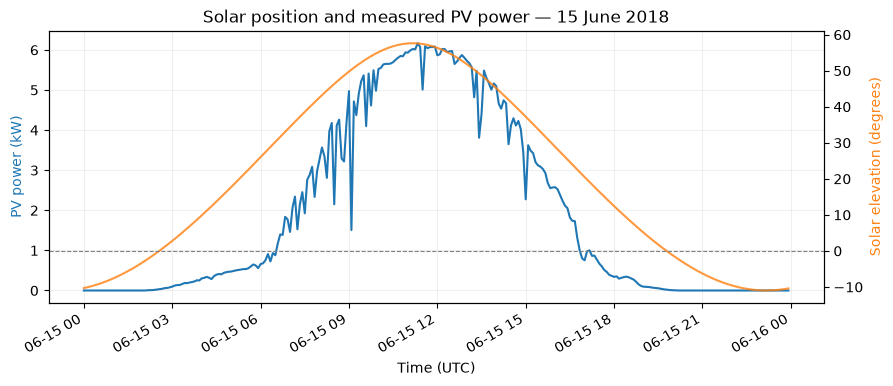

In [4]:
example_day = "2018-06-15"
solar_day = f2.loc[example_day]
pv_day = source.loc[example_day, "P_Solar[kW]"]
assert len(solar_day) == len(pv_day) == 288

fig, ax_power = plt.subplots(figsize=(10, 4))
ax_elevation = ax_power.twinx()
ax_power.plot(pv_day.index, pv_day, color="tab:blue", label="Measured PV power")
ax_elevation.plot(
    solar_day.index,
    solar_day["solar_elevation_deg"],
    color="tab:orange",
    alpha=0.8,
    label="Solar elevation",
)
ax_elevation.axhline(0, color="gray", linewidth=0.8, linestyle="--")
ax_power.set_ylabel("PV power (kW)", color="tab:blue")
ax_elevation.set_ylabel("Solar elevation (degrees)", color="tab:orange")
ax_power.set_xlabel("Time (UTC)")
ax_power.set_title("Solar position and measured PV power — 15 June 2018")
ax_power.grid(alpha=0.2)
fig.autofmt_xdate()
plt.show()


## 5. Lunar and Sun–Moon features (F3)

We calculate lunar positions with **Skyfield** and the **JPL DE440s** ephemeris. The continuous F3 block contains nine values:

- sine and cosine of the Moon–Sun phase angle;
- sine and cosine of the Moon's ecliptic longitude;
- sine and cosine of the Sun's ecliptic longitude;
- lunar ecliptic latitude, illuminated fraction, and Earth–Moon distance.

To keep memory use manageable, we calculate these features in batches and join them in timestamp order.

In [5]:
ephemeris_file = PROJECT_ROOT / "ephemeris" / "de440s.bsp"
if not ephemeris_file.is_file():
    raise FileNotFoundError(
        f"Astronomical ephemeris missing: {ephemeris_file}. "
        "Use the DE440s file from the established project astronomical setup."
    )

ephemeris = load_jpl_ephemeris(ephemeris_file)

batch_size = 8192
lunar_parts = []
for first in range(0, len(timestamps), batch_size):
    batch_times = timestamps[first:first + batch_size]
    lunar_parts.append(build_lunar_f3_features(batch_times, ephemeris))
f3 = pd.concat(lunar_parts, axis=0)

assert f3.index.equals(timestamps)
assert f3.shape == (len(timestamps), 9)
assert f3.columns.is_unique
assert np.isfinite(f3.to_numpy(dtype=float)).all()
assert f3["moon_illumination_fraction"].between(0, 1).all()
assert f3["earth_moon_distance_km"].gt(0).all()

print("Lunar and Sun–Moon variables:", f3.shape[1])
display(f3.head(3))


Lunar and Sun–Moon variables: 9


,moon_phase_sin,moon_phase_cos,moon_longitude_sin,moon_longitude_cos,sun_ecliptic_longitude_sin,sun_ecliptic_longitude_cos,moon_ecliptic_latitude_deg,moon_illumination_fraction,earth_moon_distance_km
Timestamp,,,,,,,,,
2018-06-01 00:00:00+00:00,-0.450911,-0.892569,-0.991950,0.126629,0.942482,0.334256,2.552827,0.946135,404012.840592
2018-06-01 00:05:00+00:00,-0.451504,-0.892269,-0.991858,0.127346,0.942502,0.334201,2.549630,0.945987,404017.839327
2018-06-01 00:10:00+00:00,-0.452097,-0.891969,-0.991766,0.128062,0.942521,0.334147,2.546432,0.945839,404022.829368


## 6. Check the Sun–Moon phase calculation

The Moon–Sun phase angle is calculated from the difference between the Moon's and Sun's apparent tropical ecliptic longitudes. We check a few timestamps independently against the sine and cosine values in the F3 table.

These same longitudes also provide the astronomical starting point for constructing Panchang variables.

In [6]:
positions = np.linspace(0, len(timestamps) - 1, 7, dtype=int)
sample_times = timestamps[positions]
longitudes = tropical_longitudes_for_solete(sample_times, ephemeris)
phase_deg = moon_sun_phase_angle_deg(
    longitudes["sun_tropical_longitude_deg"],
    longitudes["moon_tropical_longitude_deg"],
)

np.testing.assert_allclose(
    f3.loc[sample_times, "moon_phase_sin"].to_numpy(),
    np.sin(np.deg2rad(phase_deg)),
    rtol=0,
    atol=1e-10,
)
np.testing.assert_allclose(
    f3.loc[sample_times, "moon_phase_cos"].to_numpy(),
    np.cos(np.deg2rad(phase_deg)),
    rtol=0,
    atol=1e-10,
)

phase_check = longitudes.copy()
phase_check["moon_sun_phase_deg"] = phase_deg
print("Sample phase-angle check:")
display(phase_check.round(3))


Sample phase-angle check:


,sun_tropical_longitude_deg,moon_tropical_longitude_deg,moon_sun_phase_deg
Timestamp,,,
2018-06-01 00:00:00+00:00,70.473,277.275,206.802
2018-08-16 04:00:00+00:00,143.260,207.278,64.018
2018-10-31 08:00:00+00:00,217.841,123.130,265.289
2019-01-15 12:00:00+00:00,295.039,39.405,104.366
2019-04-01 16:00:00+00:00,11.637,330.607,318.970
2019-06-16 20:00:00+00:00,85.393,259.180,173.787
2019-09-01 00:00:00+00:00,158.288,180.568,22.280


## 7. Summary of the astronomical feature groups

The feature hierarchy adds these deterministic blocks to the historical forecasting inputs. All three tables use the same UTC row timestamps and can be aligned with forecast-valid timestamps when building the forecasting dataset.

In [7]:
feature_blocks = pd.DataFrame([
    {"feature_group": "F1 — Gregorian", "variables_added": f1.shape[1]},
    {"feature_group": "F2 — Solar", "variables_added": f2.shape[1]},
    {"feature_group": "F3 — Continuous lunar", "variables_added": f3.shape[1]},
])
feature_blocks["cumulative_with_118_F0_variables"] = (
    118 + feature_blocks["variables_added"].cumsum()
)
display(feature_blocks)

assert f1.index.equals(f2.index) and f2.index.equals(f3.index)
assert len(set(f1.columns) & set(f2.columns)) == 0
assert len(set(f1.columns) & set(f3.columns)) == 0
assert len(set(f2.columns) & set(f3.columns)) == 0
assert feature_blocks["cumulative_with_118_F0_variables"].tolist() == [133, 138, 147]
assert np.isfinite(pd.concat([f1, f2, f3], axis=1).to_numpy(dtype=float)).all()

print("NOTEBOOK 03: ASTRONOMICAL FEATURES CHECKS PASSED")


,feature_group,variables_added,cumulative_with_118_F0_variables
0,F1 — Gregorian,15,133
1,F2 — Solar,5,138
2,F3 — Continuous lunar,9,147


NOTEBOOK 03: ASTRONOMICAL FEATURES CHECKS PASSED


## What we learned

- The Gregorian representation contributes **15 variables**.
- Solar geometry contributes **5 variables**, including a geometric daylight indicator.
- Continuous lunar and Sun–Moon astronomy contributes **9 variables**.
- The shared time index and the **two-minute astronomical reference offset** keep these features aligned with the SOLETE measurement grid.
- The Sun–Moon phase calculation agrees with the continuous F3 phase encoding at the checked timestamps.

**Next:** Notebook 04 will use these astronomical definitions to calculate Tithi, Paksha, Karana, Nakshatra, and Yoga and encode the Panchang feature block.